# DMulti-MADS with OMADS: the Running Example

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L12/L12_dmulti_mads_omads_running_example.ipynb)
### MECH 559 - Systems Optimization - L12
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Examples* section of the lecture (slide *Running example*). In the previous
notebook we wrote DMulti-MADS ourselves. Here we solve the lecture's constrained running example with
**OMADS**, the Python MADS package used in this course, whose `poll` module runs DMulti-MADS when it is
given two or more objectives. We also build a reference front with a gradient-based method, so that
we can judge OMADS's answer instead of trusting it.

## Learning objectives

1. Write a multiobjective blackbox for OMADS and set up a Pareto study (`nobj`, `is_pareto`, `w_plus`).
2. Extract the approximate Pareto front and Pareto set from the evaluation history, and check it against a
   reference.
3. Compare runs correctly with the hypervolume (same reference point for all runs).
4. Explain the effect of the budget, $w^+$, the random seed and a search step on the result.

In [1]:
# %pip install OMADS==2612.1

In [2]:
import contextlib
import io
import os
import tempfile
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from OMADS import mads, poll

os.environ.setdefault("PYTHONIOENCODING", "utf-8")    # OMADS prints Unicode progress bars
plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"feasible": "#1D5FA8", "infeasible": "#C9CCD1", "front": "#D1495B", "ref": "#2A9D5C",
          "runs": ["#1D5FA8", "#D1495B", "#2A9D5C", "#EDAE49", "#7B2CBF"]}
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print(f"OMADS {version('OMADS')}, NumPy {version('numpy')}, SciPy {version('scipy')}")

OMADS 2612.1, NumPy 2.5.5, SciPy 1.18.1


---
## 1. The running example

$$
\begin{aligned}
\min_{\mathbf{x} \in [-10, 10]^6}\quad & f^{(1)}(\mathbf{x}) = x_1^2 + x_2^2 + x_3^2 + x_4^2 + x_5^2 + x_6^2 \\
\min_{\mathbf{x} \in [-10, 10]^6}\quad & f^{(2)}(\mathbf{x}) = -25(x_1 - 1)^2 + (x_2 - 1)^2 + (x_3 - 1)^2 + (x_4 - 1)^2 + (x_5 - 1)^2 + (x_6 - 1)^2 \\
\text{s.t.}\quad & x_1 + x_2 - 2 \ge 0, \quad 6 - x_1 - x_2 \ge 0, \quad 2 - x_2 + x_1 \ge 0, \quad 2 - x_1 + 3x_2 \ge 0, \\
& 4 - (x_3 - 3)^2 - x_4 \ge 0, \quad (x_5 - 3)^2 + x_6 - 4 \ge 0 .
\end{aligned}
$$

$f^{(1)}$ wants every variable near 0; the term $-25(x_1 - 1)^2$ of $f^{(2)}$ wants $x_1$ as far from 1 as
the constraints allow. The four linear constraints on $(x_1, x_2)$ form a polygon, so $x_1$ cannot go
beyond 5.

An OMADS blackbox takes the vector $\mathbf{x}$ and returns `[objectives, constraints]`, with the
constraints written as $c_j(\mathbf{x}) \le 0$. Every $g(\mathbf{x}) \ge 0$ above becomes $c = -g \le 0$.

In [3]:
def running_example(x):
    x = np.asarray(x, dtype=float)
    f1 = np.sum(x ** 2)
    f2 = -25 * (x[0] - 1) ** 2 + np.sum((x[1:] - 1) ** 2)
    c = [2 - x[0] - x[1],                        # x1 + x2 - 2 >= 0
         x[0] + x[1] - 6,                        # 6 - x1 - x2 >= 0
         x[1] - x[0] - 2,                        # 2 - x2 + x1 >= 0
         x[0] - 3 * x[1] - 2,                    # 2 - x1 + 3 x2 >= 0
         (x[2] - 3) ** 2 + x[3] - 4,             # 4 - (x3 - 3)^2 - x4 >= 0
         4 - (x[4] - 3) ** 2 - x[5]]             # (x5 - 3)^2 + x6 - 4 >= 0
    return [[float(f1), float(f2)], [float(ci) for ci in c]]


LB, UB = [-10.0] * 6, [10.0] * 6
X0 = [2.0, 2.0, 2.0, 2.0, 2.0, 5.0]
f0, c0 = running_example(X0)
print(f"x0 = {X0}: F = {f0}, max constraint = {max(c0)} (feasible: {max(c0) <= 0})")

x0 = [2.0, 2.0, 2.0, 2.0, 2.0, 5.0]: F = [45.0, -5.0], max constraint = -1.0 (feasible: True)


---
## 2. A reference front

Before running the blackbox solver, we compute a reference with gradients, which we can do here because
the functions are smooth and cheap (a real blackbox would not allow it):

- the two **single-objective** minima, which give the ideal point and the ends of the front;
- the **$\varepsilon$-constraint** front of the previous notebooks: $\min f^{(1)}$ s.t. $f^{(2)} \le \varepsilon$,
  for 50 values of $\varepsilon$, each with 10 random SLSQP starts. This takes about a minute.

In [4]:
CONS = [{"type": "ineq", "fun": (lambda x, j=j: -running_example(x)[1][j])} for j in range(6)]


def best_slsqp(objective, extra_cons=(), n_starts=10, seed=0):
    rs = np.random.default_rng(seed)
    best = None
    for _ in range(n_starts):
        r = minimize(objective, rs.uniform(-3, 6, 6), method="SLSQP", bounds=list(zip(LB, UB)),
                     constraints=CONS + list(extra_cons), options={"ftol": 1e-10, "maxiter": 500})
        f, c = running_example(r.x)
        ok = max(c) <= 1e-6 and all(con["fun"](r.x) >= -1e-6 for con in extra_cons)
        if ok and (best is None or objective(r.x) < objective(best)):
            best = r.x
    return best


t0 = time.perf_counter()
x_f1 = best_slsqp(lambda x: running_example(x)[0][0], n_starts=30)
x_f2 = best_slsqp(lambda x: running_example(x)[0][1], n_starts=30)
F_f1, F_f2 = running_example(x_f1)[0], running_example(x_f2)[0]
reference = [F_f1, F_f2]
for eps in np.linspace(F_f2[1], F_f1[1], 52)[1:-1]:
    x = best_slsqp(lambda x: running_example(x)[0][0],
                   [{"type": "ineq", "fun": lambda x, e=eps: e - running_example(x)[0][1]}])
    if x is not None:
        reference.append(running_example(x)[0])
reference = np.array(sorted(reference))
IDEAL = np.array([F_f1[0], F_f2[1]])
print(f"min f1 = {F_f1[0]:.4f} at x = {np.round(x_f1, 3)}  (f2 = {F_f1[1]:.3f})")
print(f"min f2 = {F_f2[1]:.4f} at x = {np.round(x_f2, 3)}  (f1 = {F_f2[0]:.3f})")
print(f"ideal point = {np.round(IDEAL, 3)}; reference front: {len(reference)} points in "
      f"{time.perf_counter() - t0:.0f} s")

min f1 = 2.9427 at x = [ 1.     1.     0.943 -0.229 -0.    -0.   ]  (f2 = 3.515)
min f2 = -399.9337 at x = [5.    1.    1.248 0.929 1.    1.   ]  (f1 = 30.420)
ideal point = [   2.943 -399.934]; reference front: 52 points in 35 s


The front runs from $F \approx (2.94, 3.51)$ (all variables near 0 or 1) to $F \approx (30.4, -399.9)$
($x_1 = 5$, the corner of the polygon). The ideal point $(2.94, -399.9)$ is far from both ends: the two
objectives are strongly contradictory.

---
## 3. Setting up OMADS for a Pareto study

OMADS takes a dictionary with three parts. The entries specific to multiobjective problems are marked
with *.

| Entry | Meaning |
|---|---|
| `evaluator.blackbox` | the Python function, returning `[objectives, constraints]` |
| `param.baseline`, `lb`, `ub` | starting point and bounds |
| `param.nobj` * | number of objectives (here 2) |
| `param.is_pareto` * | `True`: build a list of non-dominated points (DMulti-MADS) |
| `param.fun_names` * | one name per objective |
| `param.w_plus` * | the $w^+$ of Algorithm 3 (default 3) |
| `param.ref_point` * | reference point of the hypervolume that OMADS reports (optional) |
| `options.budget`, `seed` | evaluation budget and random seed (the poll directions are random) |

`poll.main` runs DMulti-MADS without a search step, as in our implementation; `mads.main` adds a
sampling search (Section 6). OMADS prints a progress bar on every evaluation, so the helper below runs it
quietly in a scratch folder, and logs every evaluation so that we can plot what it did.

In [5]:
def solve_omads(problem, baseline, lb, ub, budget=2000, seed=0, w_plus=3, ref_point=None, search=False):
    """Run a biobjective OMADS study quietly. Returns (OMADS output dict, evaluations DataFrame, seconds)."""
    n, log = len(lb), []

    def blackbox(x):
        f, c = problem(x)
        log.append([*x, *f, max(c) <= 0])
        return [f, c]

    param = {"baseline": list(baseline), "lb": list(lb), "ub": list(ub), "nobj": 2, "is_pareto": True,
             "var_names": [f"x{i + 1}" for i in range(n)], "fun_names": ["f1", "f2"], "w_plus": w_plus,
             "scaling": 10.0, "post_dir": tempfile.mkdtemp(), "name": "mo"}
    if ref_point is not None:
        param["ref_point"] = list(ref_point)
    options = {"seed": seed, "budget": budget, "tol": 1e-9, "display": False, "save_results": False,
               "check_cache": True, "store_cache": True, "opportunistic": False}
    data = {"evaluator": {"blackbox": blackbox}, "param": param, "options": options}
    if search:
        data["search"] = {"type": "sampling", "s_method": "LH", "ns": 2 * n}
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        out = (mads if search else poll).main(data)[0]
    evals = pd.DataFrame(log, columns=[*param["var_names"], "f1", "f2", "feasible"])
    return out, evals, time.perf_counter() - t0


def nondominated(F):
    F = np.asarray(F, dtype=float)
    mask = np.ones(len(F), dtype=bool)
    for i in range(len(F)):
        mask[i] = not (np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)).any()
    return mask


def hypervolume_2d(F, ref):
    F = np.asarray(F, dtype=float).reshape(-1, 2)
    F = F[np.all(F < ref, axis=1)]
    if len(F) == 0:
        return 0.0
    F = F[nondominated(F)]
    F = F[np.argsort(F[:, 0])]
    hv, f2_prev = 0.0, ref[1]
    for f1, f2 in F:
        hv += (ref[0] - f1) * (f2_prev - f2)
        f2_prev = f2
    return hv


def pareto(evals):
    """Feasible non-dominated evaluations, sorted by f1."""
    feas = evals[evals["feasible"]]
    return feas[nondominated(feas[["f1", "f2"]].to_numpy())].sort_values("f1", ignore_index=True)

In [6]:
out, evals, seconds = solve_omads(running_example, X0, LB, UB, budget=2000)
front = pareto(evals)
print(f"{len(evals)} evaluations in {seconds:.1f} s, {out['niterations']} iterations, "
      f"{evals['feasible'].mean():.0%} feasible, {len(front)} non-dominated points")
print("OMADS output keys:", list(out))

2000 evaluations in 18.9 s, 166 iterations, 35% feasible, 123 non-dominated points
OMADS output keys: ['xmin', 'fmin', 'hmin', 'Secondary fmin', 'Secondary hmin', 'nbb_evals', 'niterations', 'nb_success', 'psize', 'psuccess', 'msize', 'HV']


`out` is the summary that OMADS returns. For a Pareto study, `xmin` and `fmin` are only **one** point of
the list, and `HV` is the hypervolume of the list. The front itself is in the evaluation history: we take
the feasible evaluations and keep the non-dominated ones, which is exactly what the list contains.

---
## 4. Reading the result

### Where the evaluations went

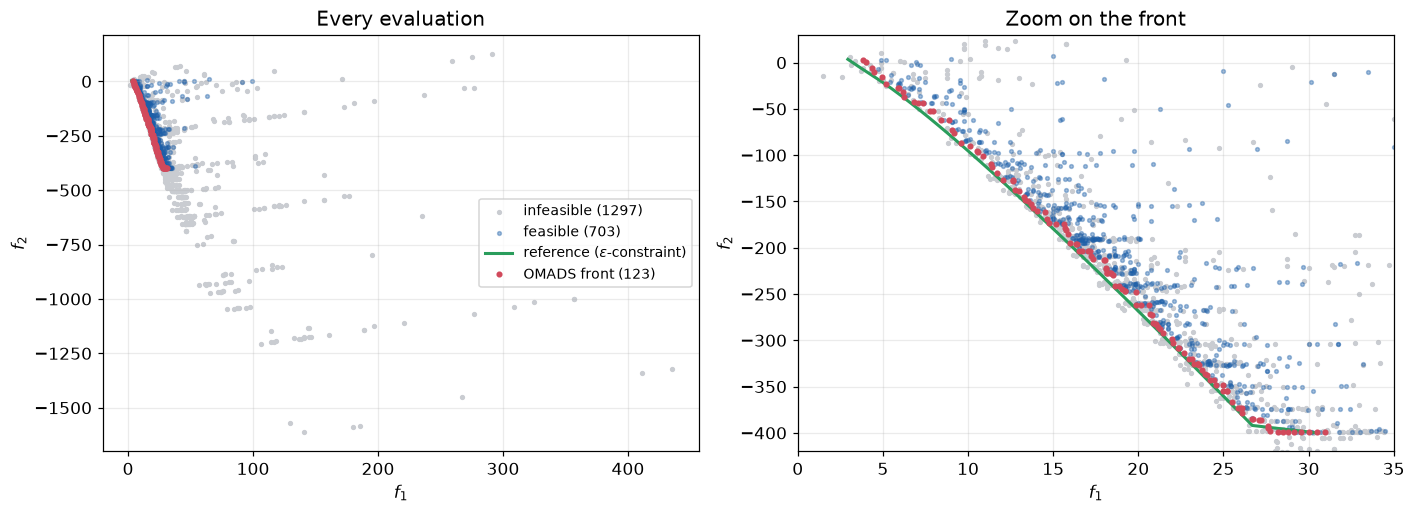

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, zoom in zip(axes, [False, True]):
    inf = evals[~evals["feasible"]]
    feas = evals[evals["feasible"]]
    ax.scatter(inf["f1"], inf["f2"], s=6, color=COLORS["infeasible"], label=f"infeasible ({len(inf)})")
    ax.scatter(feas["f1"], feas["f2"], s=6, color=COLORS["feasible"], alpha=0.4, label=f"feasible ({len(feas)})")
    ax.plot(reference[:, 0], reference[:, 1], "-", color=COLORS["ref"], lw=2, label=r"reference ($\varepsilon$-constraint)")
    ax.plot(front["f1"], front["f2"], "o", ms=3, color=COLORS["front"], label=f"OMADS front ({len(front)})")
    ax.set(xlabel="$f_1$", ylabel="$f_2$")
    if zoom:
        ax.set(xlim=(0, 35), ylim=(-420, 30), title="Zoom on the front")
    else:
        ax.set(title="Every evaluation")
        ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

What to notice:

- Most of the budget goes to the **neighbourhood of the front**: the poll works around the points of the
  list. Some points far away come from the first iterations, when the list was still a single point.
- A large share of the evaluations is **infeasible**: the front lies on the boundary of the constraints
  (the polygon in $(x_1, x_2)$), so half of the poll directions around a point of the front cross it.
  With the extreme barrier these evaluations are simply lost.
- The OMADS front follows the reference front over its whole length, slightly above it in the middle.
  The front has two pieces: an almost straight part, and a flat tail beyond $f^{(1)} \approx 27$, where
  $x_1 = 5$ has reached the corner of the polygon and $f^{(2)}$ can only improve a little more.

### The Pareto set: which variables make the trade-off?

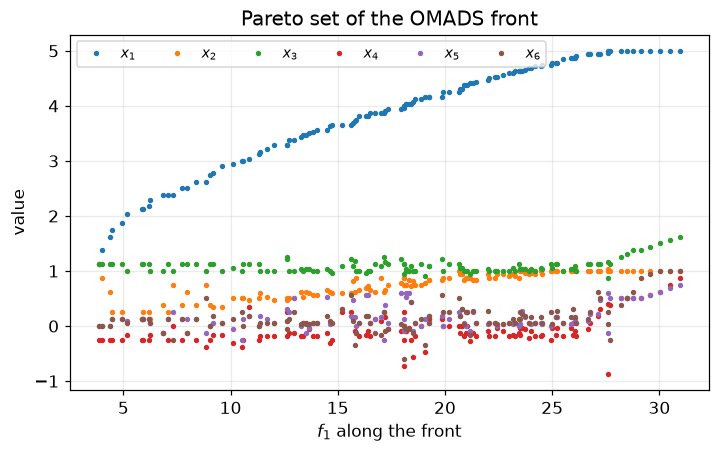

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i in range(6):
    ax.plot(front["f1"], front[f"x{i + 1}"], ".", ms=5, label=f"$x_{i + 1}$")
ax.set(xlabel="$f_1$ along the front", ylabel="value", title="Pareto set of the OMADS front")
ax.legend(ncol=6, fontsize=9, loc="upper left")
plt.show()

Along the front only $x_1$ changes in a systematic way, from about 1 to 5: moving $x_1$ away from 1
improves $f^{(2)}$ by $25(x_1 - 1)^2$ and costs $x_1^2$ in $f^{(1)}$. The other variables stay near a
compromise between 0 (best for $f^{(1)}$) and 1 (best for $f^{(2)}$), inside their constraints. On the
flat tail ($f^{(1)} > 27$) $x_1$ is stuck at 5, and the trade-off moves to $x_3, \dots, x_6$, which rise
toward 1. The scatter is the remaining inaccuracy of a finite budget.

> **Checkpoint 1.** The two ends of the front are the single-objective minima. Which end does OMADS reach
> less accurately, and why? *Answer:* the end near min $f^{(1)}$. The table below shows it: OMADS stops
> at $f^{(1)} \approx 3.9$ against $2.94$. There, $x_4 \approx -0.23$ and $x_3 \approx 0.94$ sit on the curved
> constraint $4 - (x_3 - 3)^2 - x_4 \ge 0$. The extreme barrier gives no information about how far an
> infeasible point is from feasibility, so the poll approaches curved boundaries slowly.

In [9]:
pd.DataFrame({"reference": [F_f1[0], F_f1[1], F_f2[0], F_f2[1]],
              "OMADS": [front["f1"].iloc[0], front["f2"].iloc[0], front["f1"].iloc[-1], front["f2"].iloc[-1]]},
             index=["f1 at the min-f1 end", "f2 at the min-f1 end", "f1 at the min-f2 end", "f2 at the min-f2 end"])

,reference,OMADS
f1 at the min-f1 end,2.94272,3.85938
f2 at the min-f1 end,3.51457,3.20312
f1 at the min-f2 end,30.4203,30.9688
f2 at the min-f2 end,-399.934,-399.531


### Comparing fronts: always with the same reference point

To score a front with one number we use the hypervolume. OMADS reports one in `out["HV"]`, but **without**
`ref_point` it builds its own reference from each front, so two runs cannot be compared with it. We fix
the reference point $r = (60, 10)$, a little worse than both ends of the front, and use it for every run.

In [10]:
REF = np.array([60.0, 10.0])
HV_REF = hypervolume_2d(reference, REF)
out_r, evals_r, _ = solve_omads(running_example, X0, LB, UB, budget=2000, ref_point=REF)
print(f"HV of the reference front       : {HV_REF:.1f}")
print(f"HV of the OMADS front (ours)    : {hypervolume_2d(front[['f1', 'f2']], REF):.1f}")
print(f"HV reported by OMADS, ref_point : {out_r['HV']:.1f}")
print(f"same evaluations with ref_point : {evals_r[['f1', 'f2']].equals(evals[['f1', 'f2']])}")

HV of the reference front       : 18083.1
HV of the OMADS front (ours)    : 17970.6
HV reported by OMADS, ref_point : 17970.6
same evaluations with ref_point : True


With `ref_point` set, OMADS reports the same hypervolume as our function, and it evaluated exactly the same
points: `ref_point` changes the **score**, not the search. This is the zone of interest seen from the
metric side: a tighter reference point only rewards the part of the front inside the box it defines.

The OMADS front reaches 99.4% of the reference hypervolume with 2000 evaluations. Keep in mind that the
reference is not exact either: it has only 52 points, and the hypervolume rewards a denser front, so a
long OMADS run can even score above it. Compare fronts visually as well as by hypervolume.

---
## 5. The knobs: budget, $w^+$ and the seed

Each row is one OMADS run of `poll.main`; all are scored with the same $r$. The whole cell takes about
two minutes.

In [11]:
cases = {"budget 500": dict(budget=500), "budget 1000": dict(budget=1000), "budget 2000 (default)": {},
         "budget 4000": dict(budget=4000), "w+ = 0": dict(w_plus=0), "w+ = 1": dict(w_plus=1),
         "w+ = 8": dict(w_plus=8), "seed 1": dict(seed=1), "seed 2": dict(seed=2), "seed 3": dict(seed=3)}
rows, fronts = [], {}
for label, kw in cases.items():
    o, ev, s = solve_omads(running_example, X0, LB, UB, **kw)
    fr = pareto(ev)
    fronts[label] = fr
    rows.append(dict(run=label, evaluations=len(ev), seconds=s, feasible_share=ev["feasible"].mean(),
                     front_points=len(fr), HV=hypervolume_2d(fr[["f1", "f2"]], REF),
                     HV_over_reference=hypervolume_2d(fr[["f1", "f2"]], REF) / HV_REF,
                     OMADS_HV_default_ref=o["HV"], min_f1=fr["f1"].min()))
knobs = pd.DataFrame(rows).set_index("run")
knobs

,evaluations,seconds,feasible_share,front_points,HV,HV_over_reference,OMADS_HV_default_ref,min_f1
run,,,,,,,,
budget 500,500,3.5649,0.214,26,17098.5,0.945551,0.50318,6.64062
budget 1000,1000,5.56588,0.265,50,17678,0.977601,0.537744,3.85938
budget 2000 (default),2000,11.5115,0.3515,123,17970.6,0.993783,0.568903,3.85938
budget 4000,4000,28.4747,0.3905,221,18079.2,0.999786,0.561125,3.57812
w+ = 0,2000,11.9153,0.232,62,17710.8,0.979413,0.583945,5.25
w+ = 1,2000,10.9133,0.339,81,17764.6,0.982392,0.534747,4.71875
w+ = 8,2000,11.3105,0.3445,123,18013.8,0.99617,0.55936,3.57812
seed 1,2000,11.1752,0.2905,84,17937.3,0.991937,0.555187,3.59375
seed 2,2000,12.5677,0.408,117,17951.9,0.992749,0.517841,3.59375


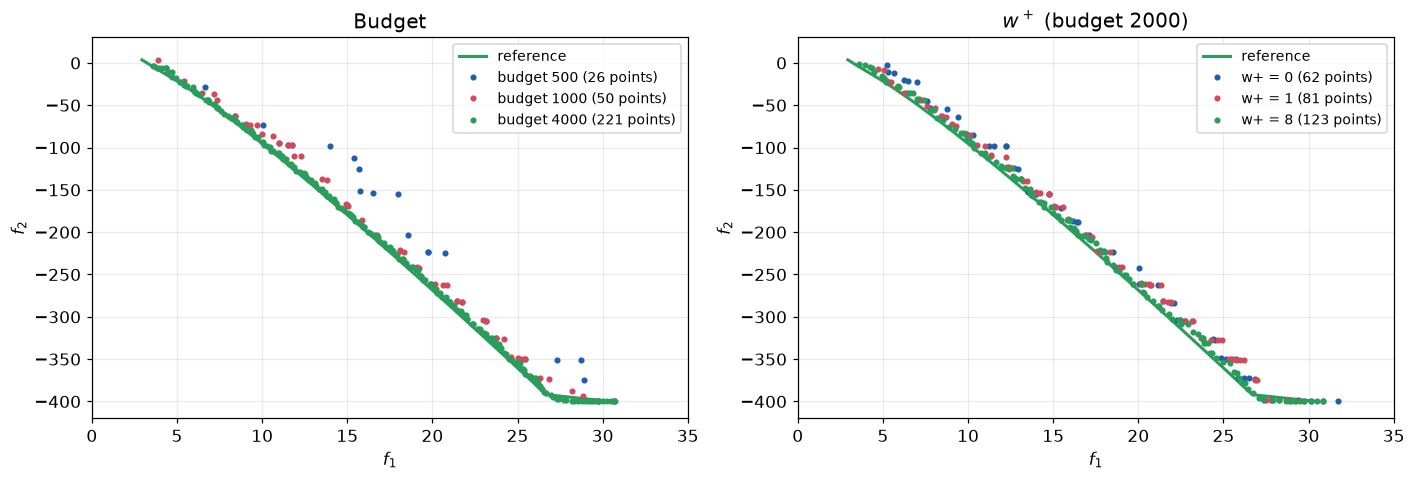

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, labels in zip(axes, [["budget 500", "budget 1000", "budget 4000"], ["w+ = 0", "w+ = 1", "w+ = 8"]]):
    ax.plot(reference[:, 0], reference[:, 1], "-", color=COLORS["ref"], lw=2, label="reference")
    for lab, c in zip(labels, COLORS["runs"]):
        fr = fronts[lab]
        ax.plot(fr["f1"], fr["f2"], "o", ms=3, color=c, label=f"{lab} ({len(fr)} points)")
    ax.set(xlabel="$f_1$", ylabel="$f_2$", xlim=(0, 35), ylim=(-420, 30))
    ax.legend(fontsize=9)
axes[0].set_title("Budget")
axes[1].set_title("$w^+$ (budget 2000)")
plt.tight_layout()
plt.show()

What to notice:

- **Budget.** The hypervolume grows with the budget with diminishing returns, while the number of front
  points grows almost linearly. With 500 evaluations the front is already in the right place but sparse,
  and it misses the min-$f^{(1)}$ end. Extra evaluations mainly fill it in.
- **$w^+$.** With $w^+ = 0$ only the points with the largest frame can be poll centres: the front has
  fewer points and its ends are less accurate. Larger values spread the effort along the whole front.
  Beyond the default $w^+ = 3$ the gain is small.
- **Seed.** The poll directions are random, so the result changes with the seed: the hypervolume varies
  by about half a percent and the number of front points by 30%. That is smaller than the effect of
  $w^+ = 0$, but larger than the difference between $w^+ = 3$ and $w^+ = 8$. One run per setting is not
  enough to rank two close settings.
- **`OMADS_HV_default_ref`**, the hypervolume OMADS reports without `ref_point`, does not even rank the
  runs in the same order as the common-reference hypervolume (compare $w^+ = 0$ with the default).
  This is the reason to always fix the reference point yourself.

---
## 6. Adding a search step

Algorithm 1 has an optional **search** before the poll. `mads.main` adds a Latin hypercube sampling
search (and a quadratic-model search) to the same poll. We compare at a budget of 1000 evaluations; the
search run takes more than a minute, because OMADS fits models at every iteration.

In [13]:
rows = []
for label, kw in {"poll only (poll.main)": dict(search=False), "search + poll (mads.main)": dict(search=True)}.items():
    o, ev, s = solve_omads(running_example, X0, LB, UB, budget=1000, **kw)
    fr = pareto(ev)
    rows.append(dict(run=label, seconds=s, iterations=o["niterations"], feasible_share=ev["feasible"].mean(),
                     front_points=len(fr), HV_over_reference=hypervolume_2d(fr[["f1", "f2"]], REF) / HV_REF))
pd.DataFrame(rows).set_index("run")

,seconds,iterations,feasible_share,front_points,HV_over_reference
run,,,,,
poll only (poll.main),6.06232,80,0.265,50,0.977601
search + poll (mads.main),87.4379,56,0.14,25,0.96713


On this problem the search does not pay: sampling points over the whole box wastes evaluations, most of
them infeasible, while the front is only reached by local polling. The search step is useful on
**multimodal** problems, where it can find a part of the front that the poll would not reach from the
current list. As always: the right setting depends on the problem, so test it at your budget.

---
## Exercises

1. **Start point.** Start OMADS from the min-$f^{(2)}$ end, $x_0 = (5, 1, 1.25, 0.93, 1, 1)$. Does the front
   change? Which end is reached more accurately now?
2. **Progressive barrier.** Count how many evaluations are infeasible with the default run. Look at the
   OMADS documentation for `constraints_type` and try `"PB"`. Does the front or the infeasible share
   change? (If nothing changes, check whether the option is used in Pareto studies.)
3. **Zone of interest.** Suppose the designer only cares about designs with $f^{(1)} \le 15$. Choose a
   reference point for that zone and rank the runs of Section 5 again. Does the ranking change?
4. **Your own problem.** Pick a two-objective problem from another course (for example mass and deflection of
   a beam). Write it as an OMADS blackbox, and compare the OMADS front with an $\varepsilon$-constraint
   front.

---
## Takeaways

1. OMADS runs DMulti-MADS when `nobj` is 2 or more and `is_pareto` is `True`. The blackbox returns the
   objectives and the constraints $c \le 0$.
2. The front is the set of feasible non-dominated evaluations. Plot it, and plot the Pareto set: it shows
   which variables drive the trade-off.
3. Verify against a reference whenever you can, and compare runs by hypervolume with **one fixed**
   reference point. The default hypervolume of a run is not comparable across runs.
4. More budget mostly densifies the front; $w^+$ spreads the effort along it; the seed matters. A search
   step helps only when the poll alone cannot reach parts of the front.